<a href="https://colab.research.google.com/github/Neha-984055/Deep-Learning/blob/main/dl_session_skill_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:

!pip install ultralytics fastapi python-multipart httpx -q


In [12]:

import torch
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

print("Libraries imported successfully!")

# Check GPU availability
if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


Libraries imported successfully!
GPU Available: Tesla T4


In [13]:

# Load YOLO model
model = YOLO("yolov8n.pt")

print("Deep Learning Model Loaded Successfully!")


Deep Learning Model Loaded Successfully!


In [14]:

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)


Saving VisionPort City Traffic Detection.png to VisionPort City Traffic Detection (1).png
Image uploaded: VisionPort City Traffic Detection (1).png


In [15]:

# Perform object detection
results = model.predict(
    source=image_path,
    device=0 if torch.cuda.is_available() else "cpu",
    conf=0.25
)

print("Object Detection Completed!")



image 1/1 /content/VisionPort City Traffic Detection (1).png: 384x640 2 persons, 3 cars, 2 motorcycles, 1 bus, 3 trucks, 6.1ms
Speed: 1.9ms preprocess, 6.1ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)
Object Detection Completed!


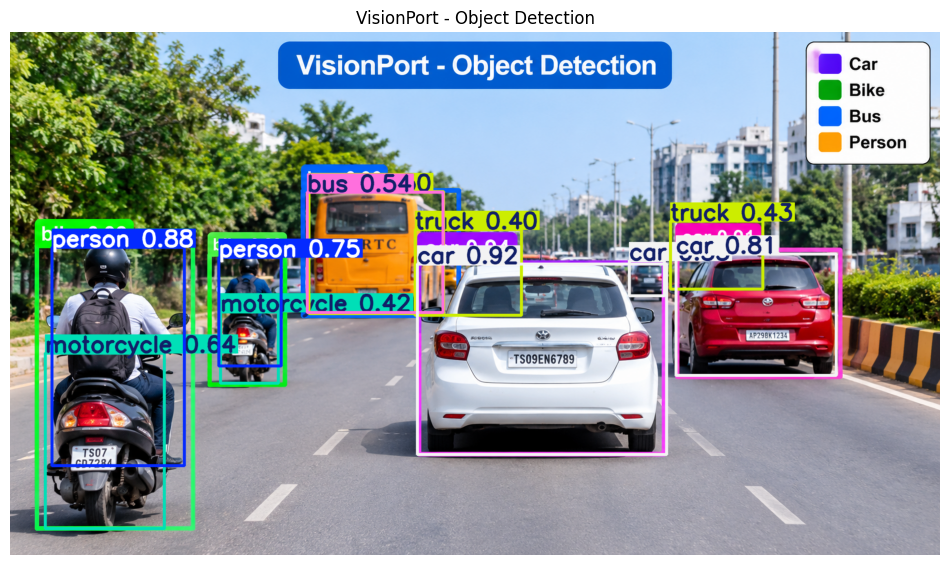

In [16]:

# Get image with bounding boxes
output_image = results[0].plot()

# Convert BGR to RGB
output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

# Display output
plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("VisionPort - Object Detection")
plt.show()


In [17]:

print("Detected Objects:")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    object_name = model.names[class_id]
    confidence = float(box.conf[0])

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )


Detected Objects:
Object: car | Confidence: 91.53 %
Object: person | Confidence: 87.93 %
Object: car | Confidence: 80.82 %
Object: person | Confidence: 75.45 %
Object: motorcycle | Confidence: 64.39 %
Object: bus | Confidence: 54.43 %
Object: truck | Confidence: 50.38 %
Object: truck | Confidence: 43.23 %
Object: motorcycle | Confidence: 42.06 %
Object: truck | Confidence: 39.86 %
Object: car | Confidence: 34.63 %


In [18]:

from fastapi import FastAPI, UploadFile, File
from fastapi.testclient import TestClient
from io import BytesIO
from PIL import Image

app = FastAPI()

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    # Read uploaded image
    image_bytes = await file.read()
    image = Image.open(BytesIO(image_bytes)).convert("RGB")

    # Send image to YOLO model
    predictions = model.predict(
        source=image,
        device=0 if torch.cuda.is_available() else "cpu",
        conf=0.25
    )

    detected_objects = []

    for box in predictions[0].boxes:
        class_id = int(box.cls[0])

        detected_objects.append({
            "object": model.names[class_id],
            "confidence": round(float(box.conf[0]), 3)
        })

    return {
        "message": "Prediction successful",
        "objects": detected_objects
    }

print("FastAPI application created!")


FastAPI application created!


In [19]:

client = TestClient(app)

with open(image_path, "rb") as image_file:

    response = client.post(
        "/predict",
        files={
            "file": (
                "traffic.jpg",
                image_file,
                "image/jpeg"
            )
        }
    )

print("Status Code:", response.status_code)

print("API Response:")
print(response.json())



0: 384x640 2 persons, 3 cars, 2 motorcycles, 1 bus, 3 trucks, 17.6ms
Speed: 1.8ms preprocess, 17.6ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
Status Code: 200
API Response:
{'message': 'Prediction successful', 'objects': [{'object': 'car', 'confidence': 0.915}, {'object': 'person', 'confidence': 0.879}, {'object': 'car', 'confidence': 0.808}, {'object': 'person', 'confidence': 0.755}, {'object': 'motorcycle', 'confidence': 0.644}, {'object': 'bus', 'confidence': 0.544}, {'object': 'truck', 'confidence': 0.504}, {'object': 'truck', 'confidence': 0.432}, {'object': 'motorcycle', 'confidence': 0.421}, {'object': 'truck', 'confidence': 0.399}, {'object': 'car', 'confidence': 0.346}]}
